# Topic 21e - Relationships

The main lesson used one scatter plot and one correlation heatmap. This notebook adds a third variable to a scatter plot by colour and by size (a bubble chart), and uses a heatmap for a grid of category totals - not just correlation - to make the sequential-vs-diverging choice concrete.

Work through it after reading section 6 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## A third variable, by colour

Quantity and revenue correlate at r = 0.41 overall. Colouring the same scatter by `segment` tests whether that relationship is the same for every kind of customer, or whether it is really three different relationships averaged together.

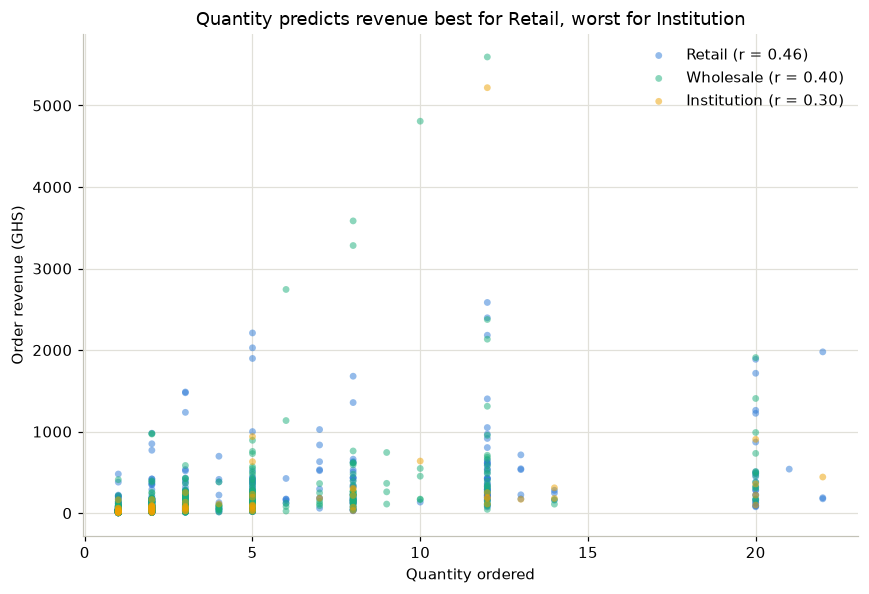

In [3]:
segment_order = ["Retail", "Wholesale", "Institution"]

fig, ax = plt.subplots(figsize=(8, 5.5))
for segment in segment_order:
    subset = analysis[analysis["segment"] == segment]
    r = subset["quantity"].corr(subset["revenue_ghs"])
    ax.scatter(subset["quantity"], subset["revenue_ghs"], s=20, alpha=0.5,
               color=SEGMENT_COLOR[segment], edgecolors="none",
               label=f"{segment} (r = {r:.2f})")

ax.set_title("Quantity predicts revenue best for Retail, worst for Institution")
ax.set_xlabel("Quantity ordered")
ax.set_ylabel("Order revenue (GHS)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

This is the same idea as the zone-split line chart in 21c: an aggregate number (r = 0.41 for everyone) can average away real differences between groups. Colour by category here is doing identity work - telling the three segments apart - which is exactly the job categorical colour is for for, per the chart-selection rule.

---

## A third *numeric* variable, by size: the bubble chart

A bubble chart is a scatter plot where marker **size** encodes a third number. Here: population on the x-axis, revenue on the y-axis, and profit as the bubble size - three numbers about each region in one chart.

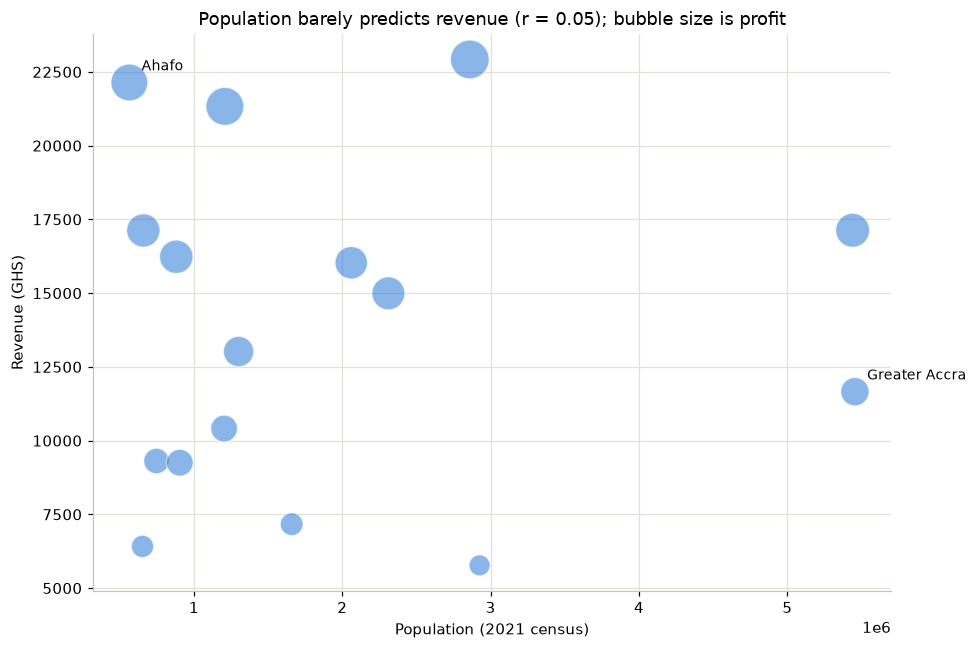

Greater Accra: population 5,455,692 - revenue rank 10 of 16
Ahafo: population 564,668 - revenue rank 2 of 16


In [4]:
region_rev = analysis.groupby("region")["revenue_ghs"].sum()
region_profit = analysis.groupby("region")["profit_ghs"].sum()
regions_full = regions.set_index("region").join(region_rev.rename("revenue_ghs")).join(
    region_profit.rename("profit_ghs")).dropna()

fig, ax = plt.subplots(figsize=(9, 6))
sizes = regions_full["profit_ghs"] / regions_full["profit_ghs"].max() * 600 + 40
ax.scatter(regions_full["population_2021"], regions_full["revenue_ghs"],
           s=sizes, alpha=0.55, color=PALETTE["blue"], edgecolors="white", linewidth=0.8)

for standout in ["Greater Accra", "Ahafo"]:
    row = regions_full.loc[standout]
    ax.annotate(standout, xy=(row["population_2021"], row["revenue_ghs"]),
                xytext=(8, 8), textcoords="offset points", fontsize=9)

r = regions_full["population_2021"].corr(regions_full["revenue_ghs"])
ax.set_title(f"Population barely predicts revenue (r = {r:.2f}); bubble size is profit")
ax.set_xlabel("Population (2021 census)")
ax.set_ylabel("Revenue (GHS)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

print("Greater Accra: population", f"{regions_full.loc['Greater Accra', 'population_2021']:,.0f}",
      "- revenue rank", int((regions_full['revenue_ghs'] > regions_full.loc['Greater Accra', 'revenue_ghs']).sum()) + 1, "of 16")
print("Ahafo: population", f"{regions_full.loc['Ahafo', 'population_2021']:,.0f}",
      "- revenue rank", int((regions_full['revenue_ghs'] > regions_full.loc['Ahafo', 'revenue_ghs']).sum()) + 1, "of 16")

Greater Accra is Ghana's most populous region by a wide margin and ranks only 10th of 16 by revenue; Ahafo has one of the smallest populations and ranks 2nd. That is the r = 0.05 from the main lesson's heatmap made concrete - population tells you almost nothing about which regions this business should prioritise, which is itself a useful, if negative, finding.

The size scaling (`sizes = ... / max * 600 + 40`) matters: without the `+ 40` floor, the smallest bubbles shrink to an invisible point, and without dividing by the maximum first, bubble sizes would not be comparable between charts with different profit scales.

---

## A heatmap for magnitude, not correlation

The main lesson's heatmap was diverging because correlation has a sign. A heatmap of revenue by zone and category has no sign - every cell is a non-negative amount of money - so it takes the **sequential** treatment: one hue, light to dark, more is simply more.

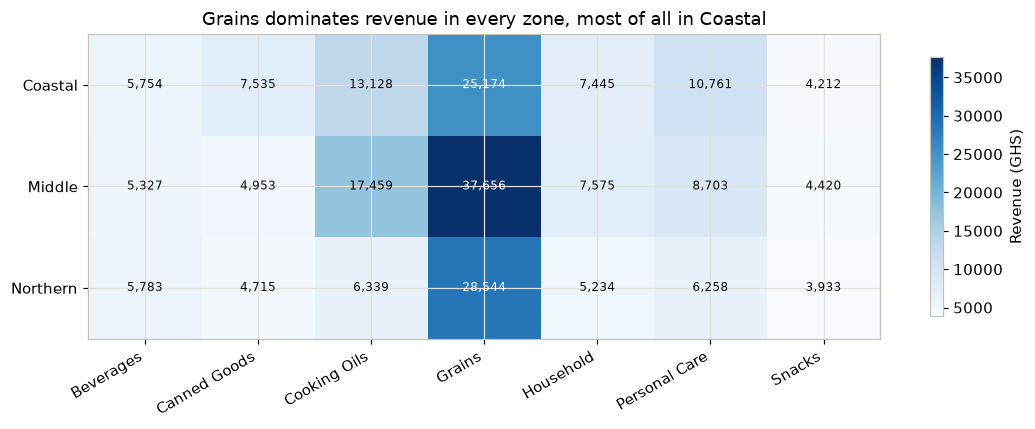

In [5]:
pivot = analysis.pivot_table(index="zone", columns="category", values="revenue_ghs", aggfunc="sum")
zone_order = ["Coastal", "Middle", "Northern"]
pivot = pivot.loc[zone_order]

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        value = pivot.values[i, j]
        ax.text(j, i, f"{value:,.0f}", ha="center", va="center",
                 color="white" if value > pivot.values.max() * 0.6 else INK, fontsize=8)
ax.set_title("Grains dominates revenue in every zone, most of all in Coastal")
fig.colorbar(im, ax=ax, shrink=0.85, label="Revenue (GHS)")
fig.tight_layout()
plt.show()

Same chart type, two different colour rules, chosen by what the numbers mean - that is the point of the chart-selection rule's "colour job" column, not a coincidence of these two examples. A rainbow colormap (`"jet"`, `"rainbow"`) would pass as "more colourful" on either heatmap and be wrong on both: it has no natural zero, invents visual bands at arbitrary cutoffs, and is famously hard to read for anyone with colour-vision deficiency.

### Try It 5 - margin, not revenue

Build the same sequential heatmap, but of **profit margin** (`profit_ghs / revenue_ghs * 100`) by zone and category instead of raw revenue. Does the category that dominates *revenue* (Grains) also dominate *margin*? Answer in a comment, with the two numbers.

In [6]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [21d - Distributions](topic21d_distributions.ipynb)
- Next: [21f - Composition and seaborn](topic21f_composition_and_seaborn.ipynb)